**LOAN APPROVAL CLASSIFICATION**

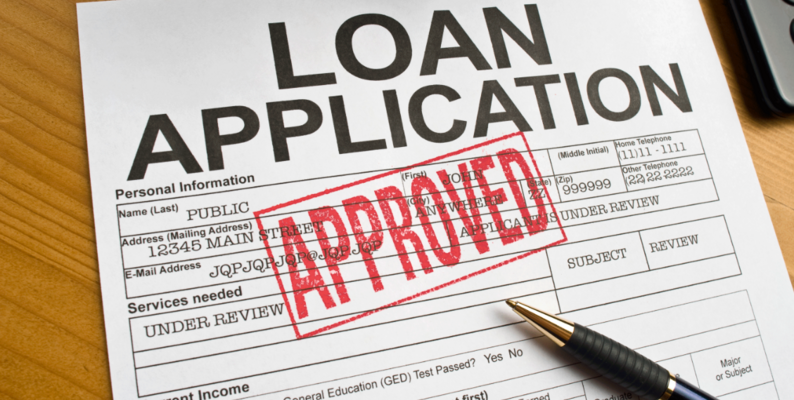

In [1]:
#import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix,classification_report,accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [2]:
#load the data
df = pd.read_csv("loan_data.csv")
df.head()

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1


EDA

In [3]:
#check top few rows
df.head()

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1


In [4]:
#check bottom few rows
df.tail()

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
44995,27.0,male,Associate,47971.0,6,RENT,15000.0,MEDICAL,15.66,0.31,3.0,645,No,1
44996,37.0,female,Associate,65800.0,17,RENT,9000.0,HOMEIMPROVEMENT,14.07,0.14,11.0,621,No,1
44997,33.0,male,Associate,56942.0,7,RENT,2771.0,DEBTCONSOLIDATION,10.02,0.05,10.0,668,No,1
44998,29.0,male,Bachelor,33164.0,4,RENT,12000.0,EDUCATION,13.23,0.36,6.0,604,No,1
44999,24.0,male,High School,51609.0,1,RENT,6665.0,DEBTCONSOLIDATION,17.05,0.13,3.0,628,No,1


In [5]:
#check info of dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  float64
 1   person_gender                   45000 non-null  str    
 2   person_education                45000 non-null  str    
 3   person_income                   45000 non-null  float64
 4   person_emp_exp                  45000 non-null  int64  
 5   person_home_ownership           45000 non-null  str    
 6   loan_amnt                       45000 non-null  float64
 7   loan_intent                     45000 non-null  str    
 8   loan_int_rate                   45000 non-null  float64
 9   loan_percent_income             45000 non-null  float64
 10  cb_person_cred_hist_length      45000 non-null  float64
 11  credit_score                    45000 non-null  int64  
 12  previous_loan_defaults_on_file  45000 non-n

In [6]:
#check null values
df.isnull().sum()

person_age                        0
person_gender                     0
person_education                  0
person_income                     0
person_emp_exp                    0
person_home_ownership             0
loan_amnt                         0
loan_intent                       0
loan_int_rate                     0
loan_percent_income               0
cb_person_cred_hist_length        0
credit_score                      0
previous_loan_defaults_on_file    0
loan_status                       0
dtype: int64

In [7]:
#check duplicate rows
df[df.duplicated()]

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status


In [8]:
#convert age into int type
df["person_age"] = df["person_age"].astype(int)

In [9]:
#summary of dataset
df.describe()

,person_age,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,loan_status
count,45000.000000,4.500000e+04,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000
mean,27.764178,8.031905e+04,5.410333,9583.157556,11.006606,0.139725,5.867489,632.608756,0.222222
std,6.045108,8.042250e+04,6.063532,6314.886691,2.978808,0.087212,3.879702,50.435865,0.415744
min,20.000000,8.000000e+03,0.000000,500.000000,5.420000,0.000000,2.000000,390.000000,0.000000
25%,24.000000,4.720400e+04,1.000000,5000.000000,8.590000,0.070000,3.000000,601.000000,0.000000
50%,26.000000,6.704800e+04,4.000000,8000.000000,11.010000,0.120000,4.000000,640.000000,0.000000
75%,30.000000,9.578925e+04,8.000000,12237.250000,12.990000,0.190000,8.000000,670.000000,0.000000
max,144.000000,7.200766e+06,125.000000,35000.000000,20.000000,0.660000,30.000000,850.000000,1.000000


<Axes: xlabel='loan_status', ylabel='count'>

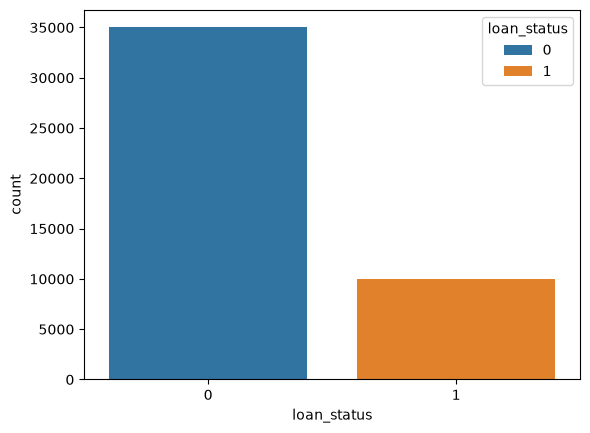

In [10]:
sns.countplot(x="loan_status",data=df,hue="loan_status")

<Axes: xlabel='person_age', ylabel='Count'>

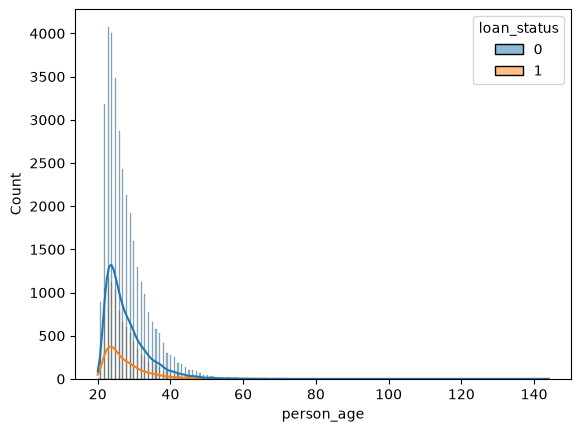

In [11]:
sns.histplot(x="person_age",data=df,hue="loan_status",kde=True)

Conclusion: People mainly from the age of 20-40 are applying for loan.

<Axes: xlabel='loan_status', ylabel='person_income'>

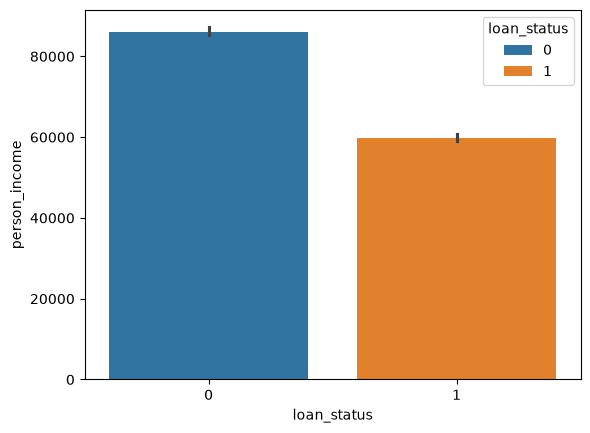

In [12]:
sns.barplot(x="loan_status",y="person_income",data=df,hue="loan_status")

*Multi Model Training*

In [13]:
#Divide the data into input and output features
X = df.drop("loan_status",axis=1)
y = df.loan_status

In [14]:
#split the data into training and testing datasets
Xtrain,Xtest,ytrain,ytest = train_test_split(X,y,test_size=0.3,random_state=42)

In [15]:
#separate numeric and object columns
num_cols = Xtrain.select_dtypes(include="number").columns
cat_cols = Xtrain.select_dtypes(include="object").columns

C:\Users\lenovo\AppData\Local\Temp\ipykernel_17092\4099034795.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = Xtrain.select_dtypes(include="object").columns


In [16]:
#initialize all the model pipelines
models = {"Logistic Regression":Pipeline([
                                ("preprocessor",ColumnTransformer([("scaler",StandardScaler(),num_cols),("encoder",OneHotEncoder(),cat_cols)])),
                                ("model",LogisticRegression(class_weight="balanced"))
                            ]),

            "Naive Bayes": Pipeline([
                            ("preprocessor",ColumnTransformer([("scaler",StandardScaler(),num_cols),("encoder",OneHotEncoder(),cat_cols)])),
                            ("model",GaussianNB())
                        ]),

            "SVM":Pipeline([
                    ("preprocessor",ColumnTransformer([("scaler",StandardScaler(),num_cols),("encoder",OneHotEncoder(),cat_cols)])),
                    ("model",SVC())
                ]),

            "Decision Tree": Pipeline([
                            ("preprocessor",ColumnTransformer([("scaler",StandardScaler(),num_cols),("encoder",OneHotEncoder(),cat_cols)])),
                            ("model",DecisionTreeClassifier(max_depth=6))
                        ]),

            "Random Forest":Pipeline([
                            ("preprocessor",ColumnTransformer([("scaler",StandardScaler(),num_cols),("encoder",OneHotEncoder(),cat_cols)])),
                            ("model",RandomForestClassifier(n_estimators=100,max_depth=6,random_state=42))
                        ])
          
          }

In [17]:
#Train the multiple pipelines and save the accuracy
model_perf = {}
for model_name,pipeline in models.items():
    #train pipelines
    pipeline.fit(Xtrain,ytrain)
    #predictions
    ypred = pipeline.predict(Xtest)
    #accuracy
    accuracy  = accuracy_score(ytest,ypred)
    #save model metrics
    model_perf[model_name] = accuracy



In [18]:
#Save Model performance table
perf_df = pd.Series(model_perf)
perf_df = pd.DataFrame(perf_df,columns=["accuracy"])
perf_df.to_csv("models_perf_dataset.csv")
perf_df

,accuracy
Logistic Regression,0.856667
Naive Bayes,0.732741
SVM,0.913704
Decision Tree,0.911259
Random Forest,0.918889


In [19]:
#fetch best model and metrics
best = max(model_perf.items(),key=lambda x: x[1])
print("Best model: ",best[0])
print("Best model accuracy: ",best[1])

Best model:  Random Forest
Best model accuracy:  0.9188888888888889


In [20]:
#save best pipeline
import pickle
best_pipeline = models[best[0]]
with open("best_model_pipeline.pkl","wb") as file:
    pickle.dump(best_pipeline,file)
    print("Best model pipeline saved successfully")

Best model pipeline saved successfully


In [21]:
#predictions
best_pipeline.predict(Xtest)

array([0, 0, 1, ..., 0, 0, 0], shape=(13500,))

In [22]:
df.to_csv('cleaned_data.csv')